# TP3 - Big Data et maladies cardiovasculaires
**Dataset : CDC BRFSS 2011–2015**

**Remarque :** J'ai changé mon sujet initial, qui portait sur le *Child Mind Institute - Problematic Internet Use*, car les données nécessaires n'étaient pas accessibles au téléchargement. J'ai donc choisi le dataset CDC BRFSS, qui contient des données volumineuses sur la santé, afin de réaliser le TP Big Data avec PySpark.

## 0- Bibliothèques

In [1]:
%pip -q install pyspark kagglehub seaborn scikit-learn joblib fastapi uvicorn

In [2]:
import os
import gc
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import joblib

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
# Création de la session Spark
spark = (SparkSession.builder
    .master("local[2]")
    .appName("TP3_BigData")
    .config("spark.driver.memory", "3g")
    .config("spark.sql.shuffle.partitions", "4")
    .getOrCreate())

spark.sparkContext.setLogLevel("ERROR")
print("Spark :", spark.version)

Spark : 4.0.5


## 1- DATA : Chargement du dataset

In [3]:
# On recupere les fichiers CSV des années 2011 jusqu'à 2015
annees = range(2011, 2016)

# On regarde d'abord si les fichiers sont déjà dans Colab
chemins = {
    int(p.stem): p
    for p in Path("/content").rglob("*.csv")
    if p.stem in [str(a) for a in annees]
}

# Sinon on télécharge automatiquement le dataset depuis Kaggle
if len(chemins) < 5:
    dossier = Path(kagglehub.dataset_download(
        "cdc/behavioral-risk-factor-surveillance-system"
    ))
    chemins = {
        int(p.stem): p
        for p in dossier.rglob("*.csv")
        if p.stem in [str(a) for a in annees]
    }

# On vérifie qu'on a bien les 5 fichiers
assert len(chemins) == 5, "Il manque des fichiers CSV"

# Affichage de la taille des fichiers en Mo
for a in annees:
    print(a, round(chemins[a].stat().st_size / 1e6, 1), "Mo")


100%|██████████| 414M/414M [00:07<00:00, 60.0MB/s]

Extracting files...


2011 748.5 Mo
2012 517.0 Mo
2013 646.1 Mo
2014 426.1 Mo
2015 541.3 Mo


## 2- EDA : Analyse des cinq années

In [6]:
# On va analyser chaque année séparément avec Spark
resultats = []

for annee in annees:
    # Lecture du fichier CSV de l'année
    df = spark.read.option("header", True).csv(str(chemins[annee]))

    # Conversion des valeurs en nombres, sans bloquer sur les valeurs incorrectes
    mental = F.expr("try_cast(MENTHLTH as double)")
    physique = F.expr("try_cast(PHYSHLTH as double)")
    generale = F.expr("try_cast(GENHLTH as double)")

    # On garde les variables utiles pour notre analyse
    data = df.select(
        F.when(mental == 88, 0)
         .when(mental.between(0, 30), mental)
         .alias("mental"),

        F.when(physique == 88, 0)
         .when(physique.between(0, 30), physique)
         .alias("physique"),

        F.when(generale.between(1, 5), generale)
         .alias("generale")
    )

    # Calcul des moyennes pour comprendre l'état de santé des personnes
    stats = data.agg(
        F.count("*").alias("participants"),
        F.round(F.avg("mental"), 2).alias("jours_mentaux"),
        F.round(F.avg("physique"), 2).alias("jours_physiques"),
        F.round(F.avg("generale"), 2).alias("sante_generale")
    ).first().asDict()

    # On stock les résultats de chaque année
    stats["annee"] = annee
    resultats.append(stats)
    print(annee, stats["participants"])

# Création d'un petit tableau pour comparer les années
resume = pd.DataFrame(resultats).sort_values("annee")
display(resume)


2011 506467
2012 475687
2013 491773
2014 464664
2015 441456


,participants,jours_mentaux,jours_physiques,sante_generale,annee
0,506467,3.47,4.36,2.58,2011
1,475687,3.51,4.39,2.58,2012
2,491773,3.37,4.35,2.58,2013
3,464664,3.27,4.22,2.56,2014
4,441456,3.32,4.30,2.56,2015


## 3- Visualisation des résultats

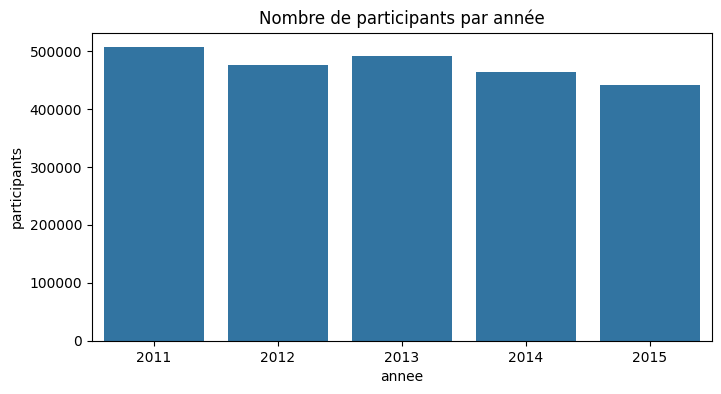

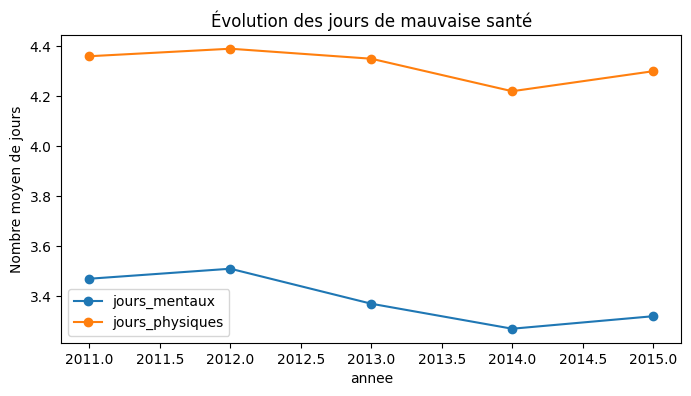

In [7]:
# Premier graphique : nombre de personnes interrogées par année
plt.figure(figsize=(8, 4))
sns.barplot(data=resume, x="annee", y="participants")
plt.title("Nombre de participants par année")
plt.show()

# Deuxième graphique : évolution de la santé mentale et physique
resume.plot(
    x="annee",
    y=["jours_mentaux", "jours_physiques"],
    marker="o",
    figsize=(8, 4)
)

plt.title("Évolution des jours de mauvaise santé")
plt.ylabel("Nombre moyen de jours")
plt.show()


## 4- PRÉTRAITEMENT : Données cardiovasculaires 2015

In [8]:
# On reprend les variables du notebook Kaggle
colonnes = [
    "_MICHD", "_RFHYPE5", "TOLDHI2", "_CHOLCHK",
    "_BMI5", "SMOKE100", "CVDSTRK3", "DIABETE3",
    "_TOTINDA", "_FRTLT1", "_VEGLT1", "_RFDRHV5",
    "HLTHPLN1", "MEDCOST", "GENHLTH", "MENTHLTH",
    "PHYSHLTH", "DIFFWALK", "SEX", "_AGEG5YR",
    "EDUCA", "INCOME2"
]

df2015 = spark.read.option("header", True).csv(str(chemins[2015]))

# On prend un échantillon pour entraîner le ML
echantillon = (
    df2015.select([
        F.col(c).cast("double").alias(c) for c in colonnes
    ])
    .sample(False, 0.20, seed=42)
    .limit(50000)
    .toPandas()
)

print("Dimensions :", echantillon.shape)
display(echantillon.head())

# On libere la mémoire de Spark
spark.stop()
del df2015, spark
gc.collect()

Dimensions : (50000, 22)


,_MICHD,_RFHYPE5,TOLDHI2,_CHOLCHK,_BMI5,SMOKE100,CVDSTRK3,DIABETE3,_TOTINDA,_FRTLT1,...,HLTHPLN1,MEDCOST,GENHLTH,MENTHLTH,PHYSHLTH,DIFFWALK,SEX,_AGEG5YR,EDUCA,INCOME2
0,NaN,2.0,1.0,1.0,3382.0,1.0,2.0,3.0,1.0,1.0,...,1.0,1.0,5.0,88.0,8.0,1.0,1.0,13.0,3.0,3.0
1,1.0,2.0,1.0,1.0,3041.0,1.0,2.0,1.0,2.0,1.0,...,1.0,2.0,5.0,30.0,30.0,1.0,2.0,9.0,5.0,1.0
2,1.0,2.0,1.0,1.0,2579.0,2.0,1.0,3.0,1.0,1.0,...,1.0,2.0,3.0,88.0,14.0,2.0,2.0,13.0,3.0,77.0
3,2.0,1.0,1.0,1.0,2349.0,1.0,2.0,3.0,2.0,2.0,...,1.0,1.0,3.0,30.0,30.0,1.0,2.0,9.0,5.0,1.0
4,2.0,2.0,1.0,1.0,2098.0,2.0,2.0,3.0,1.0,1.0,...,1.0,2.0,3.0,88.0,88.0,2.0,2.0,10.0,4.0,3.0


18

## 5- TRANSFORMATION : Nettoyage

In [9]:
# Suppression des lignes avec des valeurs manquantes
data = echantillon.dropna().copy()

# On définit les réponses valides pour chaque variable
# Les autres codes correspondent souvent aux reponses inconnues ou refusées
valides = {
    "_MICHD": [1, 2],
    "_RFHYPE5": [1, 2],
    "TOLDHI2": [1, 2],
    "_CHOLCHK": [1, 2, 3],
    "SMOKE100": [1, 2],
    "CVDSTRK3": [1, 2],
    "DIABETE3": [1, 2, 3, 4],
    "_TOTINDA": [1, 2],
    "_FRTLT1": [1, 2],
    "_VEGLT1": [1, 2],
    "_RFDRHV5": [1, 2],
    "HLTHPLN1": [1, 2],
    "MEDCOST": [1, 2],
    "GENHLTH": [1, 2, 3, 4, 5],
    "DIFFWALK": [1, 2],
    "SEX": [1, 2],
    "_AGEG5YR": list(range(1, 14)),
    "EDUCA": list(range(1, 7)),
    "INCOME2": list(range(1, 9))
}

# On garde seulement les valeurs autorisées
for c, valeurs in valides.items():
    data = data[data[c].isin(valeurs)]

# Pour ces deux variables, 88 veut dire aucun jour de mauvaise santé
for c in ["MENTHLTH", "PHYSHLTH"]:
    data = data[data[c].isin(list(range(31)) + [88])]
    data[c] = data[c].replace(88, 0)

# L'IMC est multiplié par 100 dans le fichier, donc on le remet à sa valeur normale
data = data[data["_BMI5"].between(1000, 9999)].copy()
data["_BMI5"] = data["_BMI5"] / 100

# Création de notre cible : 1 si maladie cardiovasculaire, 0 sinon
data["target"] = (data["_MICHD"] == 1).astype(int)
data = data.drop(columns="_MICHD")

# On vérifie combien de lignes restent et la répartition des classes
print("Après nettoyage :", data.shape)
print(data["target"].value_counts())


Après nettoyage : (28784, 22)
target
0    26032
1     2752
Name: count, dtype: int64


## 6- EDA : Répartition des maladies cardiovasculaires

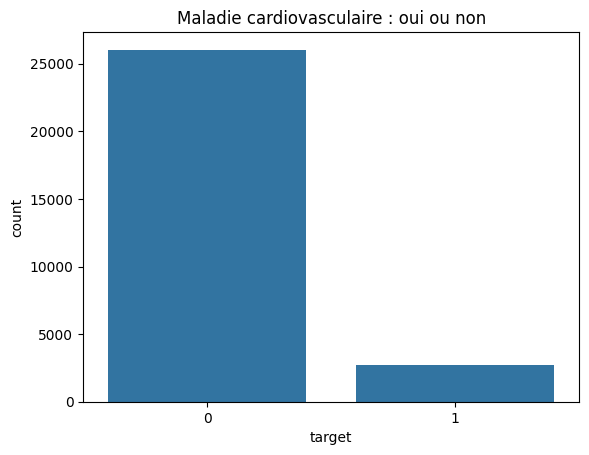

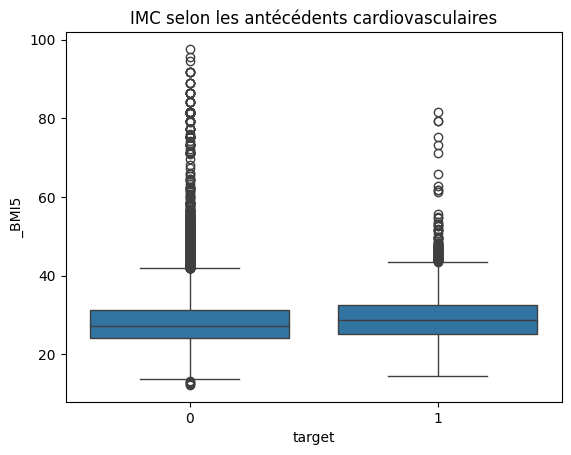

Valeurs manquantes : 0


In [10]:
# On regarde le nombre de personnes avec et sans maladie cardiovasculaire
sns.countplot(data=data, x="target")
plt.title("Maladie cardiovasculaire : oui ou non")
plt.show()

# On compare les valeurs d'IMC pour les deux groupes
sns.boxplot(data=data, x="target", y="_BMI5")
plt.title("IMC selon les antécédents cardiovasculaires")
plt.show()

# Dernière vérification des valeurs manquantes
print("Valeurs manquantes :", data.isnull().sum().sum())


## 7- MACHINE LEARNING : Deux modèles

In [11]:
# Import des outils pour préparer les données et entraîner nos modèles
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

# X contient les variables explicatives et y la maladie à prédire
X = data.drop(columns="target")
y = data["target"]

# Séparation des données en train, validation et test
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25,
    random_state=42, stratify=y_temp
)

# Séparation des variables numériques et catégorielles
num = ["_BMI5", "MENTHLTH", "PHYSHLTH"]
cat = [c for c in X.columns if c not in num]

# Normalisation des valeurs numériques et encodage des catégories
preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("fill", SimpleImputer(strategy="median")),
        ("scale", StandardScaler())
    ]), num),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat)
])

# On compare deux algorithmes classiques de classification
# class_weight permet de tenir compte du déséquilibre des classes
modeles = {
    "Logistic Regression": LogisticRegression(
        max_iter=500, class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=60, max_depth=10,
        class_weight="balanced", n_jobs=2,
        random_state=42
    )
}

entraines = {}
scores = []

# Entraînement et comparaison des deux modèles
for nom, algo in modeles.items():
    modele = Pipeline([
        ("preprocess", preprocess),
        ("model", algo)
    ])
    modele.fit(X_train, y_train)

    # On teste plusieurs seuils pour trouver celui avec le meilleur F1
    p = modele.predict_proba(X_val)[:, 1]
    seuils = np.arange(0.15, 0.81, 0.05)
    valeurs = [f1_score(y_val, p >= s) for s in seuils]
    seuil = float(seuils[np.argmax(valeurs)])

    # On garde le modèle et son meilleur seuil
    entraines[nom] = (modele, seuil)
    scores.append({
        "Modèle": nom,
        "F1 validation": max(valeurs),
        "Seuil": seuil
    })

# Tableau final pour comparer les modèles
scores = pd.DataFrame(scores).sort_values(
    "F1 validation", ascending=False
)
display(scores)


,Modèle,F1 validation,Seuil
0,Logistic Regression,0.437143,0.70
1,Random Forest,0.383729,0.55


## 8- ÉVALUATION : Résultats sur le test

Meilleur modèle : Logistic Regression
Accuracy : 0.857
Precision : 0.344
Recall : 0.553
F1 : 0.424
ROC-AUC : 0.852
Average Precision : 0.375
              precision    recall  f1-score   support

           0       0.95      0.89      0.92      5207
           1       0.34      0.55      0.42       550

    accuracy                           0.86      5757
   macro avg       0.65      0.72      0.67      5757
weighted avg       0.89      0.86      0.87      5757



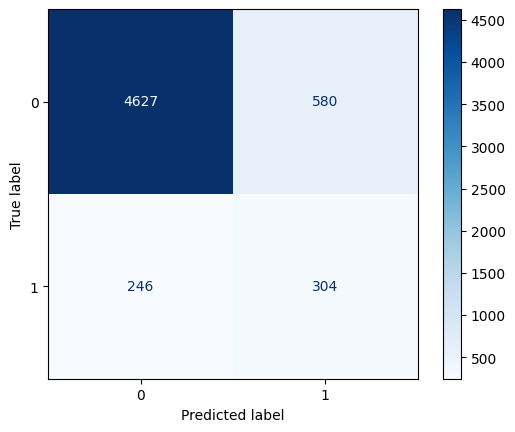

In [12]:
# Import des métriques pour évaluer les performances
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    roc_auc_score, average_precision_score,
    classification_report, ConfusionMatrixDisplay
)

# On récupère le modèle qui a obtenu le meilleur F1 sur la validation
nom = scores.iloc[0]["Modèle"]
modele, seuil = entraines[nom]

# Prédiction sur les données de test jamais utilisées pendant l'entraînement
proba = modele.predict_proba(X_test)[:, 1]
pred = (proba >= seuil).astype(int)

# Affichage des métriques pour voir si notre modèle fonctionne bien
print("Meilleur modèle :", nom)
print("Accuracy :", round(accuracy_score(y_test, pred), 3))
print("Precision :", round(precision_score(y_test, pred), 3))
print("Recall :", round(recall_score(y_test, pred), 3))
print("F1 :", round(f1_score(y_test, pred), 3))
print("ROC-AUC :", round(roc_auc_score(y_test, proba), 3))
print("Average Precision :", round(
    average_precision_score(y_test, proba), 3
))
print(classification_report(y_test, pred, zero_division=0))

# Matrice de confusion pour voir les bonnes et mauvaises prédictions
ConfusionMatrixDisplay.from_predictions(y_test, pred, cmap="Blues")
plt.show()


## 9- SAUVEGARDE : Modèle entraîné

In [13]:
objet = {
    "pipeline": modele,
    "features": X.columns.tolist(),
    "seuil": seuil
}

joblib.dump(objet, "/content/model.joblib")

print("Modèle sauvegardé")


Modèle sauvegardé
